###Exploratory Data Analysis

In [1]:
# Installing the libraries with the specified version.
!pip install scikit-learn==1.2.2 seaborn==0.13.1 matplotlib==3.7.1 numpy==1.25.2 pandas==1.5.3 -q --user

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
error: subprocess-exited-with-error

× Getting requirements to build wheel did not run successfully.
│ exit code: 1
╰─> See above for output.

note: This error originates from a subprocess, and is likely not a problem with pip.


In [3]:
# Libraries to help with reading and manipulating data
import numpy as np
import pandas as pd
import pylab
import scipy.stats as stats

# Libraries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

sns.set()

# split the data into train and test
from sklearn.model_selection import train_test_split

# to build linear regression_model
from sklearn.linear_model import LinearRegression

# to check model performance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# to build linear regression_model using statsmodels
import statsmodels.api as sm

# to compute VIF
from statsmodels.stats.outliers_influence import variance_inflation_factor


In [4]:
# to upload file from local systerm
from google.colab import files
uploaded = files.upload()

Saving ottdata.csv to ottdata.csv


In [6]:
df = pd.read_csv('ottdata.csv') # loading data to read the data
df.head()

,visitors,ad_impressions,major_sports_event,genre,dayofweek,season,views_trailer,views_content
0,1.67,1113.81,0,Horror,Wednesday,Spring,56.70,0.51
1,1.46,1498.41,1,Thriller,Friday,Fall,52.69,0.32
2,1.47,1079.19,1,Thriller,Wednesday,Fall,48.74,0.39
3,1.85,1342.77,1,Sci-Fi,Friday,Fall,49.81,0.44
4,1.46,1498.41,0,Sci-Fi,Sunday,Winter,55.83,0.46


In [7]:
print("Shape of dataset:", df.shape)  ## Print the number of rows and columns in the dataset
print("\nColumns in dataset:") ## Print a heading for column names
print(df.columns.tolist())  ## Print all column names as a list
print("\nData types:")  ## Print a heading for data types of each column
print(df.dtypes)  ## Print the data type of every column
print("\nMissing values:")  ## Print a heading for missing value counts
print(df.isnull().sum())  ## Print the total number of null/missing values in each column

Shape of dataset: (1000, 8)

Columns in dataset:
['visitors', 'ad_impressions', 'major_sports_event', 'genre', 'dayofweek', 'season', 'views_trailer', 'views_content']

Data types:
visitors              float64
ad_impressions        float64
major_sports_event      int64
genre                  object
dayofweek              object
season                 object
views_trailer         float64
views_content         float64
dtype: object

Missing values:
visitors              0
ad_impressions        0
major_sports_event    0
genre                 0
dayofweek             0
season                0
views_trailer         0
views_content         0
dtype: int64


In [8]:
df.describe(include='all') ## Summary statistics

,visitors,ad_impressions,major_sports_event,genre,dayofweek,season,views_trailer,views_content
count,1000.000000,1000.000000,1000.000000,1000,1000,1000,1000.00000,1000.000000
unique,NaN,NaN,NaN,8,7,4,NaN,NaN
top,NaN,NaN,NaN,Others,Friday,Winter,NaN,NaN
freq,NaN,NaN,NaN,255,369,257,NaN,NaN
mean,1.704290,1434.712290,0.400000,NaN,NaN,NaN,66.91559,0.473400
std,0.231973,289.534834,0.490143,NaN,NaN,NaN,35.00108,0.105914
min,1.250000,1010.870000,0.000000,NaN,NaN,NaN,30.08000,0.220000
25%,1.550000,1210.330000,0.000000,NaN,NaN,NaN,50.94750,0.400000
50%,1.700000,1383.580000,0.000000,NaN,NaN,NaN,53.96000,0.450000
75%,1.830000,1623.670000,1.000000,NaN,NaN,NaN,57.75500,0.520000


In [9]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"] ## Defining category order for better plots
season_order = ["Spring", "Summer", "Fall", "Winter"]   ## Defining category order for better plots

##**Univariate Analysis**

In [10]:
df["views_content"].describe()

,views_content
count,1000.000000
mean,0.473400
std,0.105914
min,0.220000
25%,0.400000
50%,0.450000
75%,0.520000
max,0.890000


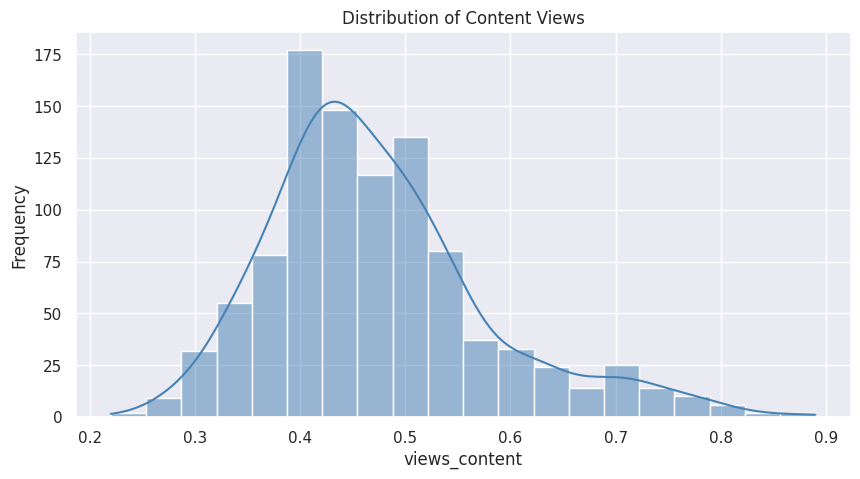

In [11]:
### Histogram Plots

plt.figure(figsize=(10, 5))  ## skewed, or concentrated around a specific range.
sns.histplot(df["views_content"], bins=20, kde=True, color="steelblue")  ## This plot helps us understand whether content views are normally distributed,
plt.title("Distribution of Content Views")
plt.xlabel("views_content")
plt.ylabel("Frequency")
plt.show()

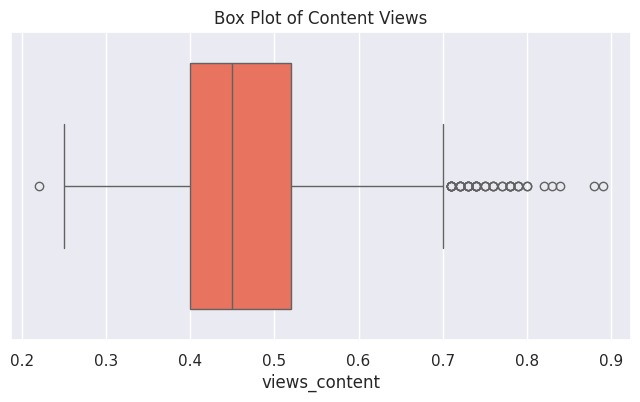

In [12]:
### Box plot

plt.figure(figsize=(8, 4))
sns.boxplot(x=df["views_content"], color="tomato") ##  Box plot helps identify spread and possible outliers in content views.
plt.title("Box Plot of Content Views")
plt.xlabel("views_content")
plt.show()

In [13]:
skew_views_content = df["views_content"].skew()  ## Calculate skewness of content views to understand distribution shape
print("Skewness of views_content:", skew_views_content)  ## Print the skewness value

Skewness of views_content: 0.9428471566302183


/tmp/ipykernel_9858/2985811973.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="genre", order=genre_counts.index, palette="viridis")


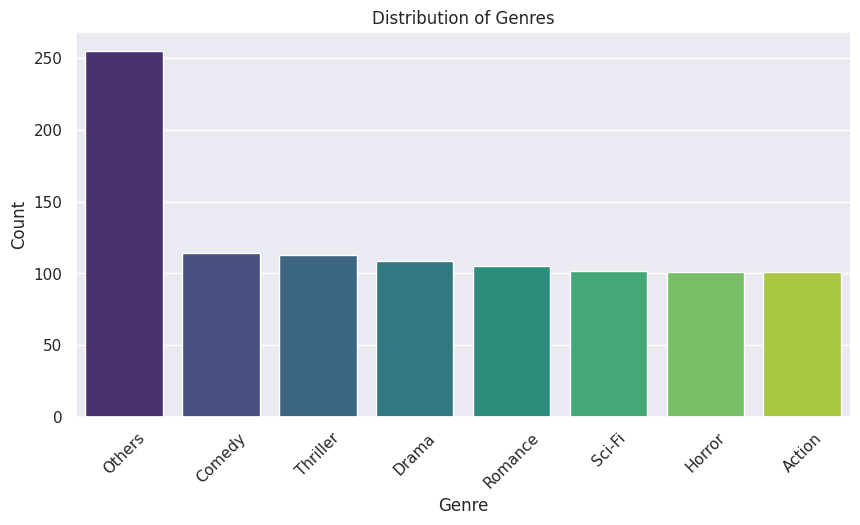

In [14]:
genre_counts = df["genre"].value_counts() ## Count the frequency of each genre in the dataset
genre_counts  ## Display genre counts
plt.figure(figsize=(10, 5))  ## Plot count plot to show the distribution of genres
sns.countplot(data=df, x="genre", order=genre_counts.index, palette="viridis")
plt.title("Distribution of Genres")
plt.xlabel("Genre")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

### Histograms and Box plots for all numerical variables

Histogram plots help us inspect the shape, spread, and possible skewness
of each numerical variable in the dataset.

Box plots help identify extreme values and outliers for numerical variables

Numerical Columns: ['visitors', 'ad_impressions', 'major_sports_event', 'views_trailer', 'views_content']


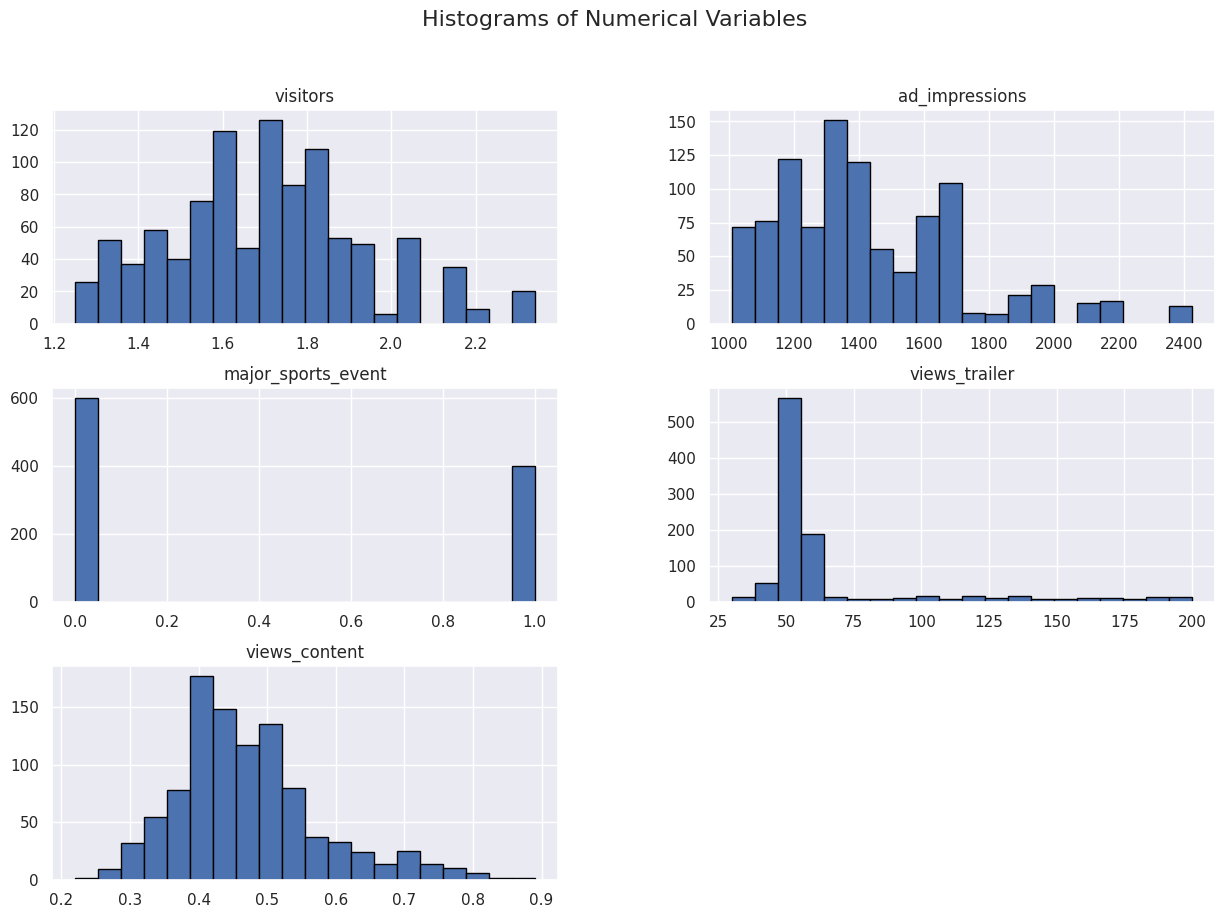

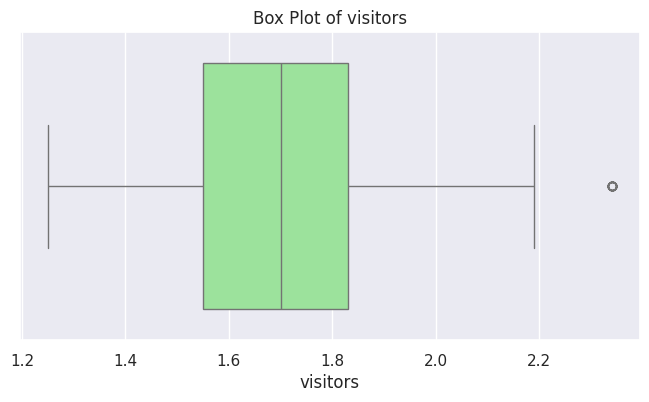

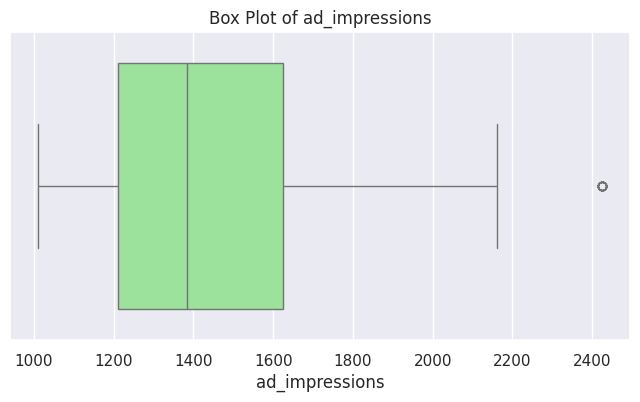

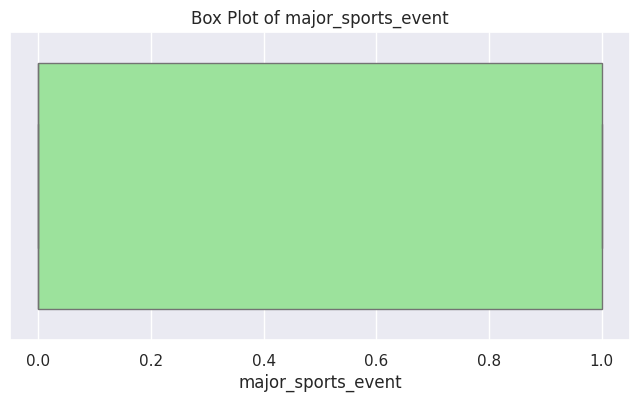

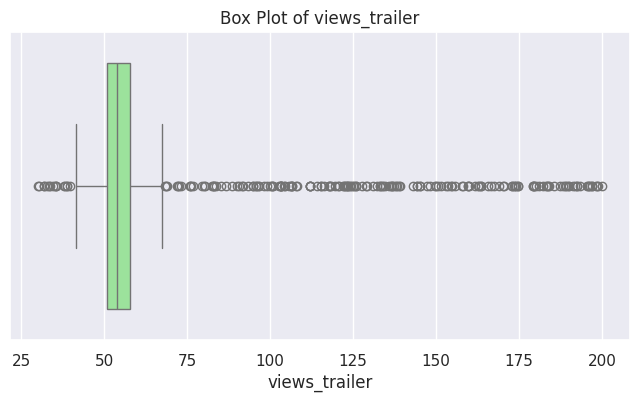

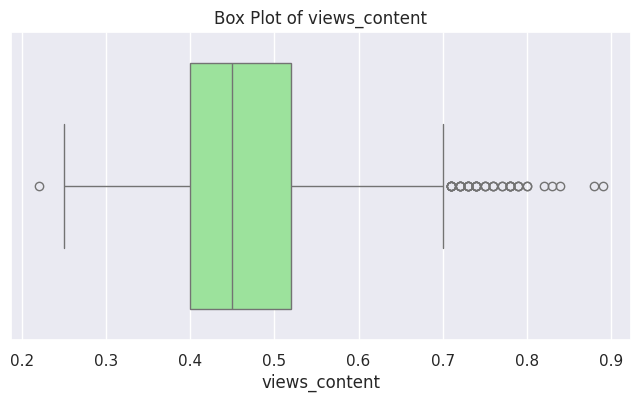

In [16]:
numeric_cols = df.select_dtypes(include=np.number).columns ## ## Select all numerical columns from the dataset
print("Numerical Columns:", numeric_cols.tolist()) ## Print the list of numerical columns
df[numeric_cols].hist(figsize=(15, 10), bins=20, edgecolor="black") ## Plot histograms for all numerical variables in the dataset
plt.suptitle("Histograms of Numerical Variables", fontsize=16) ## Add overall title to the histogram grid
plt.show()

for col in numeric_cols:  ## Plot box plots for each numerical variable one by one
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df[col], color="lightgreen")
    plt.title(f"Box Plot of {col}")
    plt.xlabel(col)
    plt.show()

##**Bivariate Analysis**

###Box plot Bar plot for viewership Variation with Day of Release

/tmp/ipykernel_9858/3920711363.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="dayofweek", y="views_content", order=day_order, palette="Set2") ## ## We can compare medians, spread, and outliers across days.


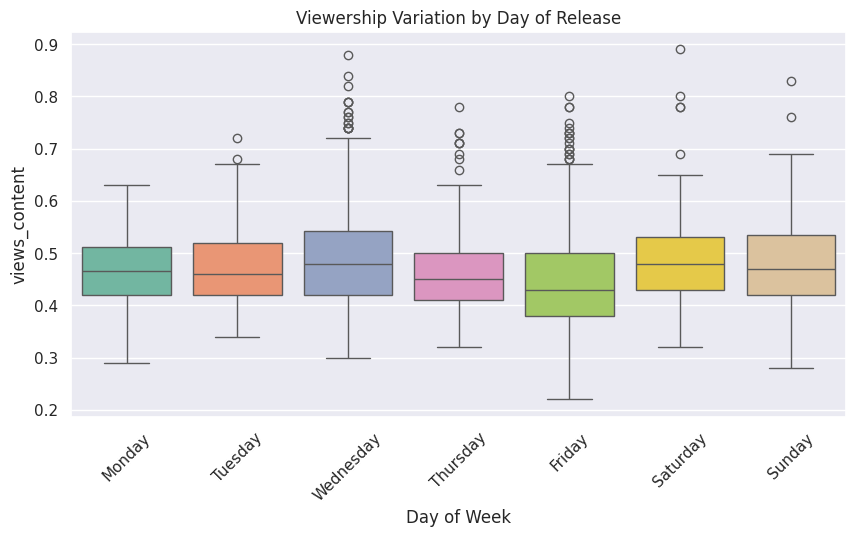

In [17]:
daywise_views = df.groupby("dayofweek")["views_content"].mean().reindex(day_order)  ## Calculate average content views for each day of the week
daywise_views ## Display average views by day
plt.figure(figsize=(10, 5)) ## Plot box plot to compare content views across different days of the week
sns.boxplot(data=df, x="dayofweek", y="views_content", order=day_order, palette="Set2") ## ## We can compare medians, spread, and outliers across days.
plt.title("Viewership Variation by Day of Release")
plt.xlabel("Day of Week")
plt.ylabel("views_content")
plt.xticks(rotation=45)
plt.show()  ## Box plot of views_content by day of week

/tmp/ipykernel_9858/2024903136.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=daywise_views.index, y=daywise_views.values, palette="coolwarm") ## Higher bars indicate days with stronger average viewership.


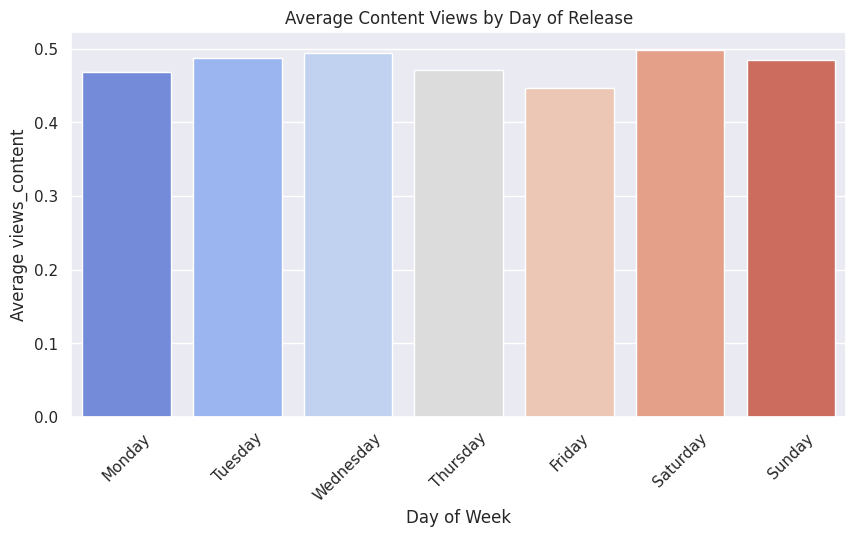

In [18]:
plt.figure(figsize=(10, 5)) ## Plot bar plot to visualize average content views by day of the week
sns.barplot(x=daywise_views.index, y=daywise_views.values, palette="coolwarm") ## Higher bars indicate days with stronger average viewership.
plt.title("Average Content Views by Day of Release")
plt.xlabel("Day of Week")
plt.ylabel("Average views_content")
plt.xticks(rotation=45)
plt.show() ## Bar plot of average views_content by day of week

###Box plot and Bar plot for viewership Variation with Season


/tmp/ipykernel_9858/470902152.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="season", y="views_content", order=season_order, palette="pastel") ## We can compare medians, spread, and outliers across seasons.


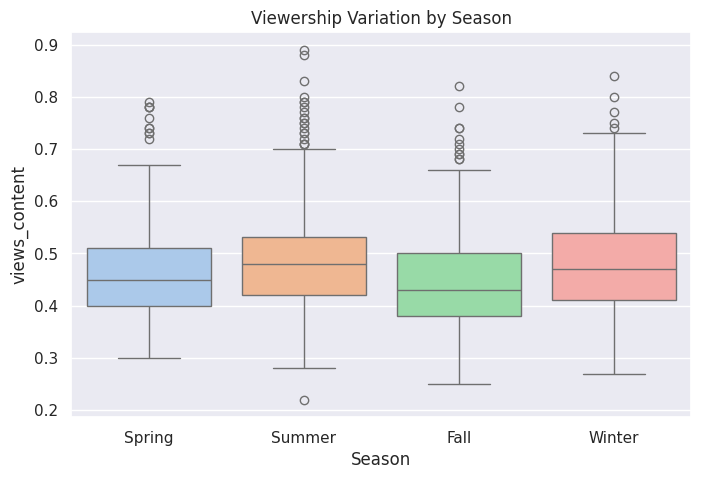

In [20]:
seasonwise_views = df.groupby("season")["views_content"].mean().reindex(season_order) ## Calculate average content views for each season
seasonwise_views ## Display average views by season
plt.figure(figsize=(8, 5))  ## Plot box plot to compare content views across seasons
sns.boxplot(data=df, x="season", y="views_content", order=season_order, palette="pastel")
plt.title("Viewership Variation by Season")
plt.xlabel("Season")
plt.ylabel("views_content")
plt.show() ## Box plot of views_content by season

/tmp/ipykernel_9858/483437384.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=seasonwise_views.index, y=seasonwise_views.values, palette="magma")


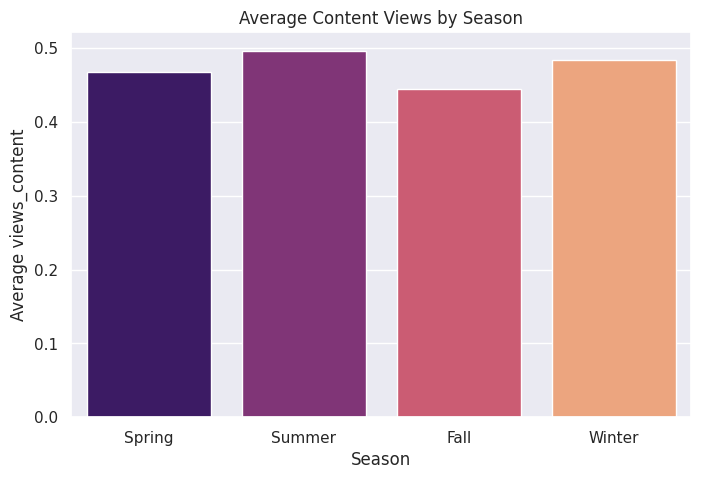

In [22]:
plt.figure(figsize=(8, 5)) ## Plot bar chart for average content views by season
sns.barplot(x=seasonwise_views.index, y=seasonwise_views.values, palette="magma")
plt.title("Average Content Views by Season")
plt.xlabel("Season")
plt.ylabel("Average views_content")
plt.show()

####Scatter plot with regression line for
Trailer Views vs Content Views, Visitors vs Content Views, Ad Impressions vs Content Views , Major Sports Events vs Content Views

In [23]:
corr_trailer_content = df["views_trailer"].corr(df["views_content"]) ## Calculate correlation between trailer views and content views
print("Correlation between views_trailer and views_content:", corr_trailer_content)  ## Print correlation value for trailer views and content views

corr_visitors_content = df["visitors"].corr(df["views_content"]) ## Calculate correlation between visitors and content views
print("Correlation between visitors and views_content:", corr_visitors_content)  ## Print correlation value for visitors and content views

corr_ads_content = df["ad_impressions"].corr(df["views_content"])  ## Calculate correlation between ad impressions and content views
print("Correlation between ad_impressions and views_content:", corr_ads_content)  ## Print correlation value for ad impressions and content views


Correlation between views_trailer and views_content: 0.753962214820536
Correlation between visitors and views_content: 0.259135761624028
Correlation between ad_impressions and views_content: 0.05002174786940941


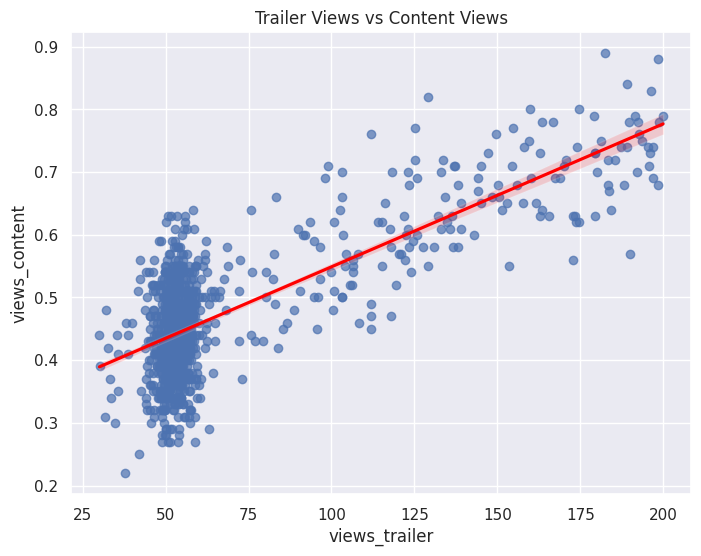

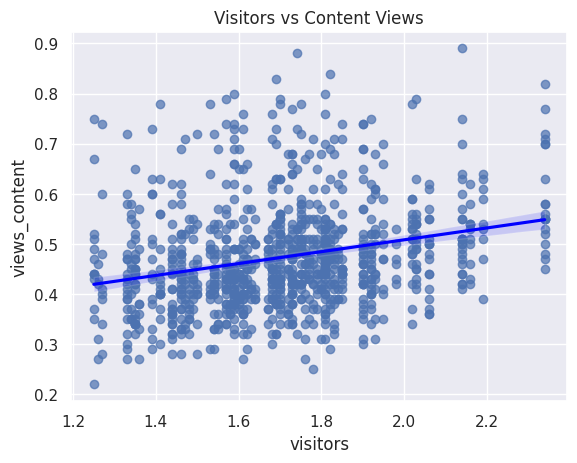

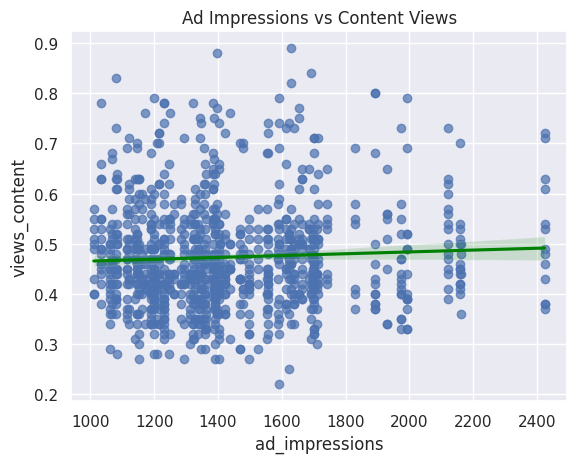

In [25]:
plt.figure(figsize=(8, 6))  ## Plot scatter plot with regression line for trailer views vs content views
sns.regplot(data=df,x="views_trailer",y="views_content",scatter_kws={"alpha": 0.7},line_kws={"color": "red"})
plt.title("Trailer Views vs Content Views")
plt.xlabel("views_trailer")
plt.ylabel("views_content")
plt.show()
sns.regplot(data=df,x="visitors",y="views_content",scatter_kws={"alpha": 0.7},line_kws={"color": "blue"}) ## Plot scatter plot with regression line for visitors vs content views
plt.title("Visitors vs Content Views")
plt.xlabel("visitors")
plt.ylabel("views_content")
plt.show()
sns.regplot(data=df,x="ad_impressions",y="views_content",scatter_kws={"alpha": 0.7},line_kws={"color": "green"})  ## Plot scatter plot with regression line for ad impressions vs content views

plt.title("Ad Impressions vs Content Views")
plt.xlabel("ad_impressions")
plt.ylabel("views_content")
plt.show()

/tmp/ipykernel_9858/1529430289.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="major_sports_event", y="views_content", palette="Set1")


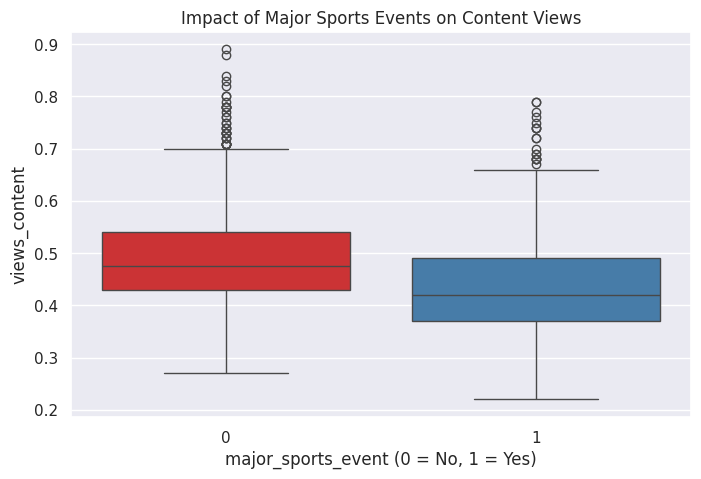

In [28]:
sports_event_views = df.groupby("major_sports_event")["views_content"].mean() ## Calculate average content views grouped by major sports event indicator
sports_event_views ## Display average views by major sports event indicator
plt.figure(figsize=(8, 5))  ## Plot box plot to compare content views across major sports events
sns.boxplot(data=df, x="major_sports_event", y="views_content", palette="Set1")
plt.title("Impact of Major Sports Events on Content Views")
plt.xlabel("major_sports_event (0 = No, 1 = Yes)")
plt.ylabel("views_content")
plt.show()

###Correlation Analysis
#####Heatmap of correlation matrix

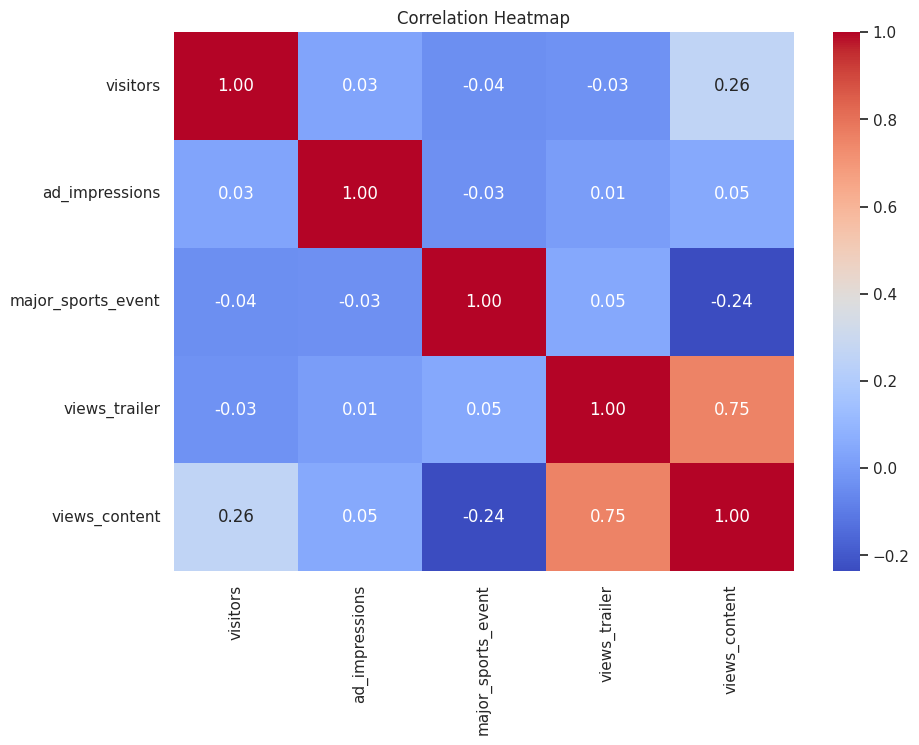

In [27]:
corr_matrix = df.corr(numeric_only=True) ## Compute correlation matrix for all numerical columns
corr_matrix ## Display the correlation matrix
plt.figure(figsize=(10, 7))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f") ## Plot heatmap to visualize correlations among numerical variables
plt.title("Correlation Heatmap")
plt.show()

###Combined Effect of Day and Season

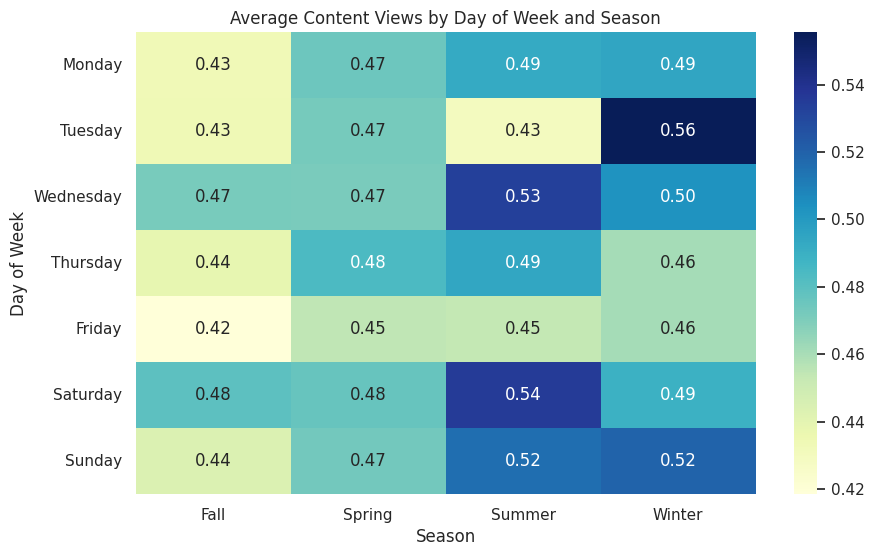

In [30]:
pivot_day_season = df.pivot_table(values="views_content",index="dayofweek",columns="season",aggfunc="mean").reindex(day_order)  ## Create pivot table for average content views by day of week and season
pivot_day_season ## Display the pivot table

plt.figure(figsize=(10, 6))
sns.heatmap(pivot_day_season, annot=True, cmap="YlGnBu", fmt=".2f")
plt.title("Average Content Views by Day of Week and Season")
plt.xlabel("Season")
plt.ylabel("Day of Week")
plt.show()

###Insights based on EDA

In [32]:
best_day = daywise_views.idxmax()  ## Find the day with the highest average content views
best_season = seasonwise_views.idxmax()  ## Find the season with the highest average content views
print("Best day for average content views:", best_day)  ## Print the best day and best season for content performance
print("Best season for average content views:", best_season)
print("Correlation between trailer views and content views:", round(corr_trailer_content, 2))  ## Print rounded correlation values for key variables
print("Correlation between visitors and content views:", round(corr_visitors_content, 2))
print("Correlation between ad impressions and content views:", round(corr_ads_content, 2))


Best day for average content views: Saturday
Best season for average content views: Summer
Correlation between trailer views and content views: 0.75
Correlation between visitors and content views: 0.26
Correlation between ad impressions and content views: 0.05


In [33]:
print("INSIGHTS FROM EDA\n")

print("1. Distribution of Content Views")
if skew_views_content > 0:
    print("- views_content is slightly right-skewed.")
    print("- Most content receives moderate viewership, while a few titles get very high views.")
else:
    print("- views_content is fairly balanced without strong right skew.")

print("\n2. Distribution of Genres")
print("- Genre distribution is uneven.")
print("- Some genres dominate the platform's content library more than others.")

print("\n3. Viewership vs Day of Release")
print(f"- {best_day} shows the highest average content viewership.")
print("- Release timing appears to influence audience engagement.")

print("\n4. Viewership vs Season")
print(f"- {best_season} has the highest average content viewership.")
print("- Seasonality may reflect festive periods, holidays, or changes in viewing habits.")

print("\n5. Trailer Views vs Content Views")
print(f"- The correlation between views_trailer and views_content is {corr_trailer_content:.2f}.")
print("- Trailer engagement appears to be a strong predictor of content success.")

print("\n6. Visitors vs Content Views")
print(f"- The correlation between visitors and views_content is {corr_visitors_content:.2f}.")
print("- Higher platform traffic generally increases content consumption.")

print("\n7. Ad Impressions vs Content Views")
print(f"- The correlation between ad_impressions and views_content is {corr_ads_content:.2f}.")
print("- Marketing exposure likely contributes positively to content performance.")

print("\n8. Impact of Major Sports Events")
if sports_event_views[1] < sports_event_views[0]:
    print("- Content released during major sports events tends to get lower viewership.")
    print("- Competing live events may divert audience attention.")
else:
    print("- Major sports events do not appear to reduce viewership significantly in this dataset.")

INSIGHTS FROM EDA

1. Distribution of Content Views
- views_content is slightly right-skewed.
- Most content receives moderate viewership, while a few titles get very high views.

2. Distribution of Genres
- Genre distribution is uneven.
- Some genres dominate the platform's content library more than others.

3. Viewership vs Day of Release
- Saturday shows the highest average content viewership.
- Release timing appears to influence audience engagement.

4. Viewership vs Season
- Summer has the highest average content viewership.
- Seasonality may reflect festive periods, holidays, or changes in viewing habits.

5. Trailer Views vs Content Views
- The correlation between views_trailer and views_content is 0.75.
- Trailer engagement appears to be a strong predictor of content success.

6. Visitors vs Content Views
- The correlation between visitors and views_content is 0.26.
- Higher platform traffic generally increases content consumption.

7. Ad Impressions vs Content Views
- The cor

###**Data preprocessing**

In [44]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [45]:
duplicate_count = df.duplicated().sum()  ## Check the number of duplicate rows in the dataset
print("Number of duplicate rows:", duplicate_count)
df = df.drop_duplicates()  ## Remove duplicate rows from the dataset
print("Shape after removing duplicates:", df.shape)  ## Confirm the new shape after removing duplicates

Number of duplicate rows: 0
Shape after removing duplicates: (1000, 8)


In [46]:
print("Missing values in each column:")
print(df.isnull().sum())  ## Check missing values in each column
num_cols = df.select_dtypes(include=np.number).columns   ## Separate numerical and categorical columns
cat_cols = df.select_dtypes(exclude=np.number).columns

for col in num_cols:  ## Fill missing values in numerical columns with median
    df[col] = df[col].fillna(df[col].median())

for col in cat_cols:  ## Fill missing values in categorical columns with mode
    df[col] = df[col].fillna(df[col].mode()[0])

print("\nMissing values after treatment:") ## Recheck missing values after treatment
print(df.isnull().sum())

Missing values in each column:
visitors              0
ad_impressions        0
major_sports_event    0
genre                 0
dayofweek             0
season                0
views_trailer         0
views_content         0
dtype: int64

Missing values after treatment:
visitors              0
ad_impressions        0
major_sports_event    0
genre                 0
dayofweek             0
season                0
views_trailer         0
views_content         0
dtype: int64


In [47]:
def cap_outliers_iqr(dataframe, column):  ## Function to cap outliers using IQR method
 Q1 = dataframe[column].quantile(0.25)  ## Calculate first quartile
 Q3 = dataframe[column].quantile(0.75)  ## Calculate third quartile
 IQR = Q3 - Q1  ## Calculate interquartile range
 lower_bound = Q1 - 1.5 * IQR   ## Define lower and upper bounds
 upper_bound = Q3 + 1.5 * IQR
 dataframe[column] = np.where(dataframe[column] < lower_bound, lower_bound, dataframe[column])  ## Cap values below lower bound and above upper bound
 dataframe[column] = np.where(dataframe[column] > upper_bound, upper_bound, dataframe[column])
 for col in num_cols:  ## Apply outlier treatment to all numerical columns
    cap_outliers_iqr(df, col)
    df.describe()  ## Display summary statistics after outlier treatment

In [48]:
df_encoded = pd.get_dummies(df, columns=["genre", "dayofweek", "season"], drop_first=True)  ## Convert categorical variables into dummy/indicator variables
df_encoded.head()  ## Display first few rows of encoded data

,visitors,ad_impressions,major_sports_event,views_trailer,views_content,genre_Comedy,genre_Drama,genre_Horror,genre_Others,genre_Romance,...,genre_Thriller,dayofweek_Monday,dayofweek_Saturday,dayofweek_Sunday,dayofweek_Thursday,dayofweek_Tuesday,dayofweek_Wednesday,season_Spring,season_Summer,season_Winter
0,1.67,1113.81,0,56.70,0.51,False,False,True,False,False,...,False,False,False,False,False,False,True,True,False,False
1,1.46,1498.41,1,52.69,0.32,False,False,False,False,False,...,True,False,False,False,False,False,False,False,False,False
2,1.47,1079.19,1,48.74,0.39,False,False,False,False,False,...,True,False,False,False,False,False,True,False,False,False
3,1.85,1342.77,1,49.81,0.44,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,1.46,1498.41,0,55.83,0.46,False,False,False,False,False,...,False,False,False,True,False,False,False,False,False,True


In [49]:
y = df_encoded["views_content"]  ## Define target variable
X = df_encoded.drop("views_content", axis=1)  ## Define feature variables by dropping target column
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)  ## Split data into training and testing sets
print("X_train shape:", X_train.shape)  ## Display shapes of training and testing sets
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (800, 20)
X_test shape: (200, 20)
y_train shape: (800,)
y_test shape: (200,)


In [51]:
scaler = StandardScaler() ## Initialize the scaler
X_train_scaled = scaler.fit_transform(X_train) ## Fit the scaler on training data and transform training data
X_test_scaled = scaler.transform(X_test) ## Use the same scaler to transform test data
print("Scaled training data sample:")
print(X_train_scaled[:5]) ## Display a sample of scaled training data

Scaled training data sample:
[[-1.99211983  0.94521368  1.21207912 -0.36171159 -0.34705645 -0.3560345
  -0.3560345   1.73784364 -0.3560345  -0.32634444 -0.35380193 -0.15171652
   3.36269123 -0.27170849 -0.34251779 -0.14734777 -0.70379479  1.72629647
  -0.5658021  -0.58889842]
 [-0.48363198 -0.33458154 -0.82502865 -0.328438   -0.34705645 -0.3560345
  -0.3560345   1.73784364 -0.3560345  -0.32634444 -0.35380193 -0.15171652
  -0.29738086 -0.27170849 -0.34251779 -0.14734777 -0.70379479 -0.57927478
  -0.5658021   1.69808573]
 [ 0.03356385 -0.14819429 -0.82502865  1.51383788 -0.34705645  2.80871659
  -0.3560345  -0.57542576 -0.3560345  -0.32634444 -0.35380193 -0.15171652
  -0.29738086 -0.27170849 -0.34251779 -0.14734777 -0.70379479 -0.57927478
  -0.5658021  -0.58889842]
 [ 0.89555691 -0.47620299 -0.82502865 -0.32331899 -0.34705645 -0.3560345
  -0.3560345  -0.57542576 -0.3560345  -0.32634444  2.82644017 -0.15171652
   3.36269123 -0.27170849 -0.34251779 -0.14734777 -0.70379479  1.72629647
  -0.

In [52]:
print("Final feature matrix shape:", X.shape)  ## Confirm final processed dataset details
print("Target variable shape:", y.shape)
X.head()  ## Display first few rows of processed feature set

Final feature matrix shape: (1000, 20)
Target variable shape: (1000,)


,visitors,ad_impressions,major_sports_event,views_trailer,genre_Comedy,genre_Drama,genre_Horror,genre_Others,genre_Romance,genre_Sci-Fi,genre_Thriller,dayofweek_Monday,dayofweek_Saturday,dayofweek_Sunday,dayofweek_Thursday,dayofweek_Tuesday,dayofweek_Wednesday,season_Spring,season_Summer,season_Winter
0,1.67,1113.81,0,56.70,False,False,True,False,False,False,False,False,False,False,False,False,True,True,False,False
1,1.46,1498.41,1,52.69,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False
2,1.47,1079.19,1,48.74,False,False,False,False,False,False,True,False,False,False,False,False,True,False,False,False
3,1.85,1342.77,1,49.81,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False
4,1.46,1498.41,0,55.83,False,False,False,False,False,True,False,False,False,True,False,False,False,False,False,True


In [53]:
from sklearn.linear_model import LinearRegression  ## Import LinearRegression model from sklearn
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error  ## Import evaluation metrics for model performance

In [61]:
df = pd.read_csv('ottdata.csv') # loading data to read the data
df.head()

,visitors,ad_impressions,major_sports_event,genre,dayofweek,season,views_trailer,views_content
0,1.67,1113.81,0,Horror,Wednesday,Spring,56.70,0.51
1,1.46,1498.41,1,Thriller,Friday,Fall,52.69,0.32
2,1.47,1079.19,1,Thriller,Wednesday,Fall,48.74,0.39
3,1.85,1342.77,1,Sci-Fi,Friday,Fall,49.81,0.44
4,1.46,1498.41,0,Sci-Fi,Sunday,Winter,55.83,0.46


In [62]:
df = df.drop_duplicates()  ## Remove duplicate rows from the dataset

for col in df.select_dtypes(include=np.number).columns:  ## Fill missing values for numerical columns
    df[col] = df[col].fillna(df[col].median())  ## Replace missing values with median

for col in df.select_dtypes(exclude=np.number).columns:  ## Fill missing values for categorical columns
    df[col] = df[col].fillna(df[col].mode()[0])  ## Replace missing values with mode

df = pd.get_dummies(df, columns=["genre", "dayofweek", "season"], drop_first=True)  ## Convert categorical variables to dummy variables
df.head()  ## Display first few rows of processed dataset

,visitors,ad_impressions,major_sports_event,views_trailer,views_content,genre_Comedy,genre_Drama,genre_Horror,genre_Others,genre_Romance,...,genre_Thriller,dayofweek_Monday,dayofweek_Saturday,dayofweek_Sunday,dayofweek_Thursday,dayofweek_Tuesday,dayofweek_Wednesday,season_Spring,season_Summer,season_Winter
0,1.67,1113.81,0,56.70,0.51,False,False,True,False,False,...,False,False,False,False,False,False,True,True,False,False
1,1.46,1498.41,1,52.69,0.32,False,False,False,False,False,...,True,False,False,False,False,False,False,False,False,False
2,1.47,1079.19,1,48.74,0.39,False,False,False,False,False,...,True,False,False,False,False,False,True,False,False,False
3,1.85,1342.77,1,49.81,0.44,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,1.46,1498.41,0,55.83,0.46,False,False,False,False,False,...,False,False,False,True,False,False,False,False,False,True


In [71]:
y = df["views_content"]  ## Define the target variable as views_content
X = df.drop("views_content", axis=1)  ## Define the feature variables by dropping the target column
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)  ## Split the data into training and testing sets
print("X_train shape:", X_train.shape)  ## Print the shape of training and testing sets
print("X_test shape:", X_test.shape)  ## Print the shape of training and testing sets
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)
scaler = StandardScaler()   ## Create an object of StandardScaler
X_train_scaled = scaler.fit_transform(X_train)  ## Fit the scaler on training data and transform
X_test_scaled = scaler.transform(X_test)  ## Use the same scaler to transform test data
model = LinearRegression()  ## Create an object of LinearRegression
model.fit(X_train_scaled, y_train)  ## Fit the model on scaled training data
y_pred = model.predict(X_test_scaled)  ## Make predictions on scaled test data
r2 = r2_score(y_test, y_pred)  ## Calculate R-squared score
mae = mean_absolute_error(y_test, y_pred)  ## Calculate Mean Absolute Error
mse = mean_squared_error(y_test, y_pred)  ## Calculate Mean Squared Error
rmse = np.sqrt(mse)  ## Calculate Root Mean Squared Error
print("R-squared:", r2)  ## Print the evaluation metrics
print("Mean Absolute Error (MAE):", mae)  ## Print the evaluation metrics
print("Mean Squared Error (MSE):", mse)  ## Print the evaluation metrics
print("Root Mean Squared Error (RMSE):", rmse)
coefficients = pd.DataFrame({"Feature": X.columns,"Coefficient": model.coef_})  ## Create a DataFrame with coefficients
coefficients["Abs_Coefficient"] = coefficients["Coefficient"].abs()  ## Calculate absolute values of coefficients
coefficients = coefficients.sort_values(by="Abs_Coefficient", ascending=False)  ## Sort coefficients by absolute value
coefficients = coefficients.drop("Abs_Coefficient", axis=1)  ## Drop the absolute value column
print("Intercept of the model:", model.intercept_)
print("MODEL INTERPRETATION\n")
print(f"R-squared value is {r2:.2f}, which shows how much variation in views_content is explained by the model.")
print(f"MAE is {mae:.2f}, which tells the average absolute error in prediction.")
print(f"RMSE is {rmse:.2f}, which shows the typical prediction error magnitude.")
print("\nTop Feature Coefficients:")  ## Print the top 10 coefficients
print(coefficients[["Feature", "Coefficient"]].head(10))

X_train shape: (800, 20)
X_test shape: (200, 20)
y_train shape: (800,)
y_test shape: (200,)
R-squared: 0.7743076305248306
Mean Absolute Error (MAE): 0.03988869442513337
Mean Squared Error (MSE): 0.00250278788397963
Root Mean Squared Error (RMSE): 0.05002787107182985
Intercept of the model: 0.47496249999999995
MODEL INTERPRETATION

R-squared value is 0.77, which shows how much variation in views_content is explained by the model.
MAE is 0.04, which tells the average absolute error in prediction.
RMSE is 0.05, which shows the typical prediction error magnitude.

Top Feature Coefficients:
                Feature  Coefficient
3         views_trailer     0.081247
0              visitors     0.029909
2    major_sports_event    -0.029237
16  dayofweek_Wednesday     0.023313
18        season_Summer     0.019118
12   dayofweek_Saturday     0.014361
19        season_Winter     0.011602
17        season_Spring     0.010063
13     dayofweek_Sunday     0.009822
11     dayofweek_Monday     0.006683


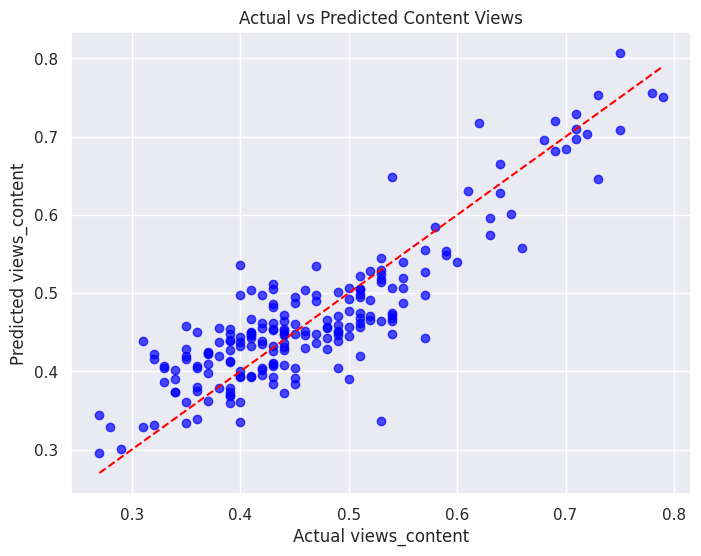

In [65]:
plt.figure(figsize=(8, 6))  ## Plot actual vs predicted views_content
plt.scatter(y_test, y_pred, alpha=0.7, color="blue")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red", linestyle="--") ## Plot reference line showing perfect prediction
plt.title("Actual vs Predicted Content Views")
plt.xlabel("Actual views_content")
plt.ylabel("Predicted views_content")
plt.show()

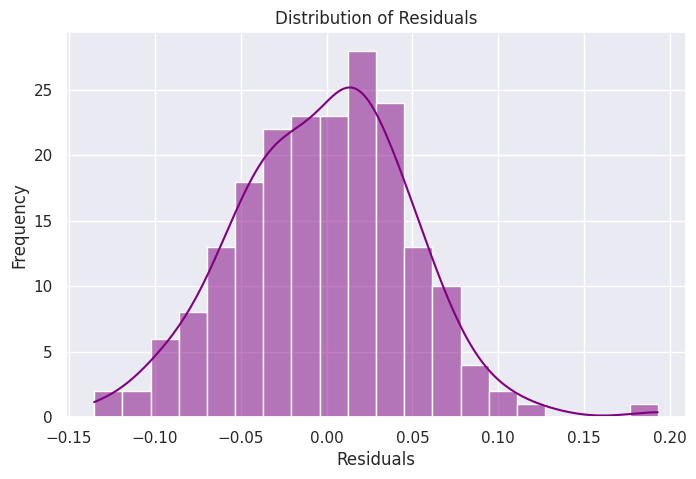

In [66]:
residuals = y_test - y_pred ## Calculate residuals as actual minus predicted values
plt.figure(figsize=(8, 5)) ## Set figure size for residual distribution plot
sns.histplot(residuals, bins=20, kde=True, color="purple") ## Plot histogram of residuals
plt.title("Distribution of Residuals") ## Add title and labels to the residual plot
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.show()

In [67]:
print("FINAL CONCLUSION\n")
print("The linear regression model helps predict first-day content viewership based on platform, marketing, timing, and genre-related factors.") ## Print conclusion about model usefulness
print("The model coefficients explain the direction and strength of each feature's impact on views_content.")  ## Print conclusion about coefficients
print("The evaluation metrics such as R-squared, MAE, MSE, and RMSE help assess how well the model performs on unseen data.")  ## Print conclusion about metrics


FINAL CONCLUSION

The linear regression model helps predict first-day content viewership based on platform, marketing, timing, and genre-related factors.
The model coefficients explain the direction and strength of each feature's impact on views_content.
The evaluation metrics such as R-squared, MAE, MSE, and RMSE help assess how well the model performs on unseen data.


###Testing the assumption of linear reggression model

In [72]:
from statsmodels.stats.stattools import durbin_watson

In [73]:
y_train_pred = model.predict(X_train_scaled) ## Predict values for the training data using the trained linear regression model
residuals = y_train - y_train_pred ## Calculate residuals by subtracting predicted values from actual values

####Linearity Assumption

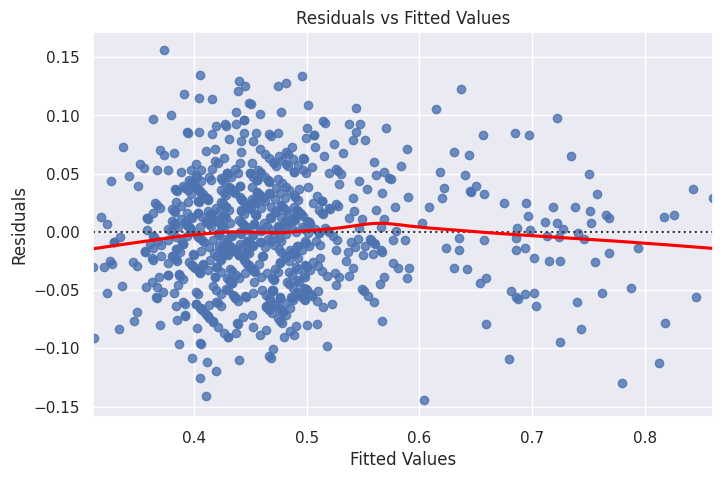

In [74]:
plt.figure(figsize=(8, 5)) ## Create a residual plot to check linearity between predictors and target
sns.residplot(x=y_train_pred, y=residuals, lowess=True, line_kws={"color": "red"}) ## Plot residuals
plt.title("Residuals vs Fitted Values") ## Add title and labels to the residual plot
plt.xlabel("Fitted Values")
plt.ylabel("Residuals")
plt.show()

###Independent Assumption

In [75]:
dw_statistic = durbin_watson(residuals) ## Calculate Durbin-Watson statistic to test autocorrelation in residuals
print("Durbin-Watson statistic:", dw_statistic) ## Print Durbin-Watson statistic

Durbin-Watson statistic: 2.0383117453811685


####Homoscedasticity Assumption

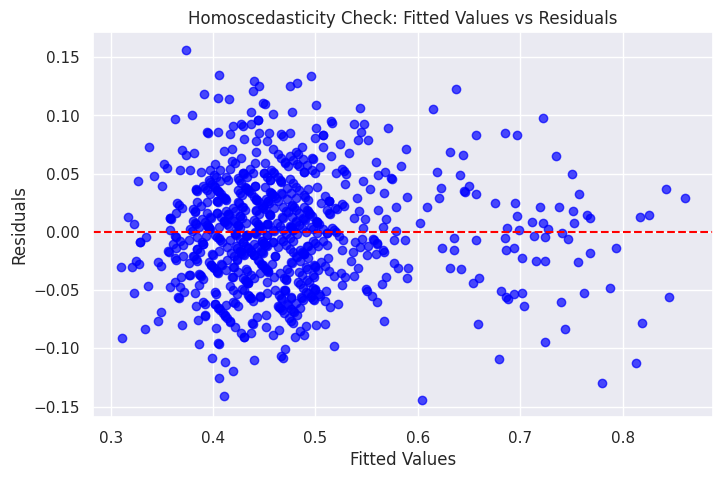

In [76]:
plt.figure(figsize=(8, 5))  ## Create scatter plot of fitted values vs residuals
plt.scatter(y_train_pred, residuals, alpha=0.7, color="blue")  ## Plot fitted values on x-axis and residuals on y-axis
plt.axhline(y=0, color="red", linestyle="--")  ## Draw a horizontal reference line at zero
plt.title("Homoscedasticity Check: Fitted Values vs Residuals")
plt.xlabel("Fitted Values")
plt.ylabel("Residuals")
plt.show()

### Normality of residuals

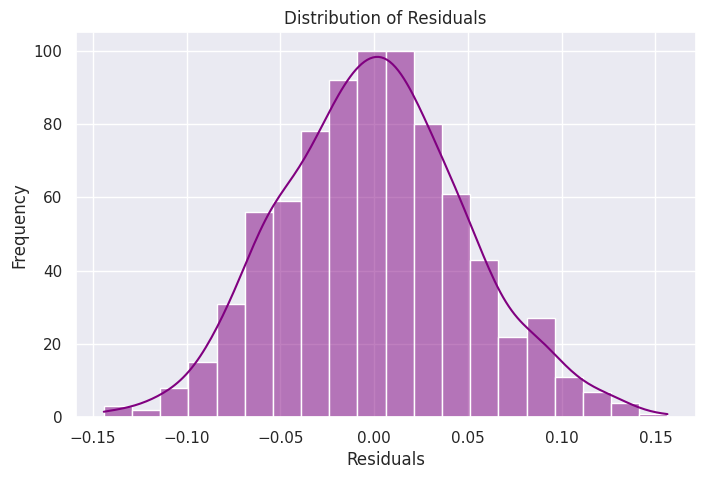

In [77]:
plt.figure(figsize=(8, 5))  ## Plot histogram of residuals to visually inspect normality
sns.histplot(residuals, bins=20, kde=True, color="purple")  ## Plot histogram with KDE line
plt.title("Distribution of Residuals")
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.show()  ## Show the histogram

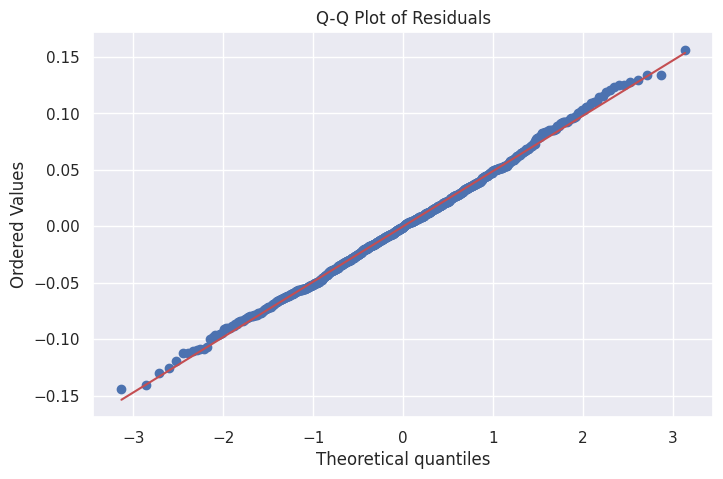

In [78]:
plt.figure(figsize=(8, 5))  ## Create Q-Q plot to compare residual distribution with normal distribution
stats.probplot(residuals, dist="norm", plot=plt)  ## Generate Q-Q plot
plt.title("Q-Q Plot of Residuals")
plt.show()

In [79]:
shapiro_test = stats.shapiro(residuals)  #### Perform Shapiro-Wilk test for normality of residuals
print("Shapiro-Wilk Test Statistic:", shapiro_test.statistic) ## Print Shapiro-Wilk test statistic and p-value
print("Shapiro-Wilk Test p-value:", shapiro_test.pvalue)

Shapiro-Wilk Test Statistic: 0.9979296712301936
Shapiro-Wilk Test p-value: 0.4378788472000393


In [80]:
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X_train.columns) ## Convert scaled training features into a DataFrame for VIF calculation
vif_data = pd.DataFrame() ## Create empty DataFrame to store VIF results
vif_data["Feature"] = X_train_scaled_df.columns ## Add feature names to the VIF table
vif_data["VIF"] = [
    variance_inflation_factor(X_train_scaled_df.values, i)  ## Calculate VIF for each feature
    for i in range(X_train_scaled_df.shape[1])
]
print(vif_data) ## Display VIF values

                Feature       VIF
0              visitors  1.023127
1        ad_impressions  1.016150
2    major_sports_event  1.050081
3         views_trailer  1.022471
4          genre_Comedy  1.895637
5           genre_Drama  1.949009
6          genre_Horror  1.960065
7          genre_Others  2.747592
8         genre_Romance  1.951780
9          genre_Sci-Fi  1.840090
10       genre_Thriller  1.953058
11     dayofweek_Monday  1.055199
12   dayofweek_Saturday  1.134784
13     dayofweek_Sunday  1.123982
14   dayofweek_Thursday  1.166168
15    dayofweek_Tuesday  1.062392
16  dayofweek_Wednesday  1.291473
17        season_Spring  1.536523
18        season_Summer  1.570254
19        season_Winter  1.559988


In [81]:
print("LINEAR REGRESSION ASSUMPTION CHECKS\n")
print("1. Linearity:") ## Print interpretation for linearity assumption
print("- Residuals should be randomly scattered around zero.")
print("- Any curve or pattern suggests non-linear relationships.")
print("\n2. Independence:") ## Print interpretation for independence assumption
print(f"- Durbin-Watson statistic = {dw_statistic:.2f}")
print("- A value near 2 indicates residuals are independent.")
print("\n3. Homoscedasticity:") ## Print interpretation for homoscedasticity
print("- Residuals should have constant spread across fitted values.")
print("- Funnel-shaped spread indicates unequal variance.")
print("\n4. Normality of Residuals:") ## Print interpretation for normality
print(f"- Shapiro-Wilk p-value = {shapiro_test.pvalue:.4f}")
print("- A p-value greater than 0.05 suggests residuals are approximately normal.")
print("\n5. Multicollinearity:") ## Print interpretation for multicollinearity
print("- VIF values should ideally be below 5.")
print("- High VIF values suggest strong correlation among predictors.")


LINEAR REGRESSION ASSUMPTION CHECKS

1. Linearity:
- Residuals should be randomly scattered around zero.
- Any curve or pattern suggests non-linear relationships.

2. Independence:
- Durbin-Watson statistic = 2.04
- A value near 2 indicates residuals are independent.

3. Homoscedasticity:
- Residuals should have constant spread across fitted values.
- Funnel-shaped spread indicates unequal variance.

4. Normality of Residuals:
- Shapiro-Wilk p-value = 0.4379
- A p-value greater than 0.05 suggests residuals are approximately normal.

5. Multicollinearity:
- VIF values should ideally be below 5.
- High VIF values suggest strong correlation among predictors.


In [82]:
print("These tests help verify whether the linear regression model is statistically reliable.") ## Print conclusion about assumption checking
print("If assumptions are violated, consider transformations, feature selection, or advanced regression methods.") ## Print suggestion if assumptions are violated
print("A model that satisfies these assumptions produces more stable and interpretable predictions.") ## Print model reliability note

These tests help verify whether the linear regression model is statistically reliable.
If assumptions are violated, consider transformations, feature selection, or advanced regression methods.
A model that satisfies these assumptions produces more stable and interpretable predictions.


###Model performance evaluation

In [83]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error ## Import evaluation metrics for regression model performance

In [85]:
y_pred = model.predict(X_test_scaled) ## Use the trained model to make predictions on the test dataset
r_squared = r2_score(y_test, y_pred)
print(f'R-squared: {r_squared:.2f}') ## Calculate R-squared value to measure how well the model explains the variance in the target
mae = mean_absolute_error(y_test, y_pred)
print(f'Mean Absolute Error (MAE): {mae:.2f}') ## Calculate Mean Absolute Error to measure the average absolute difference between actual and predicted values
mse = mean_squared_error(y_test, y_pred)
print(f'Mean Squared Error (MSE): {mse:.2f}') ## Calculate Mean Squared Error to measure the average squared difference between actual and predicted values
rmse = np.sqrt(mse)
print(f'Root Mean Squared Error (RMSE): {rmse:.2f}')  ## Print the Root Mean Squared Error

R-squared: 0.77
Mean Absolute Error (MAE): 0.04
Mean Squared Error (MSE): 0.00
Root Mean Squared Error (RMSE): 0.05


In [87]:
X_train_const = X_train.copy() # Create a copy to avoid modifying original X_train directly

# Convert boolean columns to integer (0 or 1) for statsmodels
for col in X_train_const.select_dtypes(include='bool').columns:
    X_train_const[col] = X_train_const[col].astype(int)

X_train_const = sm.add_constant(X_train_const)
ols_model = sm.OLS(y_train, X_train_const).fit()
print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:          views_content   R-squared:                       0.787
Model:                            OLS   Adj. R-squared:                  0.781
Method:                 Least Squares   F-statistic:                     143.8
Date:                Fri, 03 Apr 2026   Prob (F-statistic):          2.53e-245
Time:                        14:51:55   Log-Likelihood:                 1279.0
No. Observations:                 800   AIC:                            -2516.
Df Residuals:                     779   BIC:                            -2418.
Df Model:                          20                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                   0.0548    

In [90]:
summary_table = pd.DataFrame({                  ## Create a DataFrame to display coefficients and p-values of predictors
    "Feature": ols_model.params.index,          ## Store feature names including intercept
    "Coefficient": ols_model.params.values,     ## Store coefficient values
    "P_Value": ols_model.pvalues.values         ## Store p-values for significance testing
})
summary_table

,Feature,Coefficient,P_Value
0,const,0.054787,1.948655e-03
1,visitors,0.128909,1.121568e-54
2,ad_impressions,0.000008,1.798767e-01
3,major_sports_event,-0.059559,1.635459e-51
4,views_trailer,0.002311,1.905697e-223
5,genre_Comedy,0.004389,5.733427e-01
6,genre_Drama,0.010636,1.699553e-01
7,genre_Horror,0.009434,2.247512e-01
8,genre_Others,0.004984,4.585417e-01
9,genre_Romance,-0.001385,8.582241e-01


In [88]:
significant_predictors = summary_table[summary_table["P_Value"] < 0.05]  ## Filter predictors with p-values below 0.05
print("Significant Predictors:\n")  ## Print significant predictors
print(significant_predictors)

In [93]:
print("COMMENTS ON SIGNIFICANCE OF PREDICTORS\n")
for index, row in summary_table.iterrows():
  if row["Feature"] == "const":
        continue
  if row["P_Value"] < 0.05:
    if row["Coefficient"] > 0:
      print(f"- {row['Feature']} is statistically significant and has a positive impact on views_content.")
    elif row["Coefficient"] < 0:
      print(f"- {row['Feature']} is statistically significant and has a negative impact on views_content.")
    else:
      print(f"- {row['Feature']} is statistically significant but its coefficient is nearly zero.")
  else:
    print(f"- {row['Feature']} is not statistically significant based on its p-value.")

COMMENTS ON SIGNIFICANCE OF PREDICTORS

- visitors is statistically significant and has a positive impact on views_content.
- ad_impressions is not statistically significant based on its p-value.
- major_sports_event is statistically significant and has a negative impact on views_content.
- views_trailer is statistically significant and has a positive impact on views_content.
- genre_Comedy is not statistically significant based on its p-value.
- genre_Drama is not statistically significant based on its p-value.
- genre_Horror is not statistically significant based on its p-value.
- genre_Others is not statistically significant based on its p-value.
- genre_Romance is not statistically significant based on its p-value.
- genre_Sci-Fi is not statistically significant based on its p-value.
- genre_Thriller is not statistically significant based on its p-value.
- dayofweek_Monday is statistically significant and has a positive impact on views_content.
- dayofweek_Saturday is statistically

In [94]:
print("\nKEY TAKEAWAYS FOR THE BUSINESS\n") ## Print heading for business takeaways
if "views_trailer" in summary_table["Feature"].values:  ## Check if views_trailer is significant
    trailer_row = summary_table[summary_table["Feature"] == "views_trailer"].iloc[0]
    if trailer_row["P_Value"] < 0.05:
        print("- Trailer views are an important driver of content viewership.")
        print("- The business should invest in creating and promoting high-quality trailers.")

if "ad_impressions" in summary_table["Feature"].values: ## Check if ad_impressions is significant
    ad_row = summary_table[summary_table["Feature"] == "ad_impressions"].iloc[0]
    if ad_row["P_Value"] < 0.05:
        print("- Ad impressions significantly influence content performance.")
        print("- Marketing campaigns should be strengthened to improve title visibility.")

if "visitors" in summary_table["Feature"].values:  ## Check if visitors is significant
    visitors_row = summary_table[summary_table["Feature"] == "visitors"].iloc[0]
    if visitors_row["P_Value"] < 0.05:
        print("- Platform traffic has a meaningful effect on content views.")
        print("- Increasing platform visits can lead to higher content consumption.")

if "major_sports_event" in summary_table["Feature"].values:  ## Check whether major sports event is significant
    sports_row = summary_table[summary_table["Feature"] == "major_sports_event"].iloc[0]
    if sports_row["P_Value"] < 0.05 and sports_row["Coefficient"] < 0:
        print("- Major sports events reduce viewership.")
        print("- Important content releases should avoid clashing with large sports events.")

day_features = [feature for feature in summary_table["Feature"] if "dayofweek_" in feature]  ## Check if any day-of-week dummy variables are significant
significant_day_features = summary_table[
    (summary_table["Feature"].isin(day_features)) & (summary_table["P_Value"] < 0.05)
]

if not significant_day_features.empty:  ## Print day-based recommendation if any day variables are significant
    print("- Day of release affects content performance.")
    print("- The business should schedule releases on the best-performing days.")

season_features = [feature for feature in summary_table["Feature"] if "season_" in feature]  ## Check if any season dummy variables are significant
significant_season_features = summary_table[
    (summary_table["Feature"].isin(season_features)) & (summary_table["P_Value"] < 0.05)
]

if not significant_season_features.empty:  ## Print season-based recommendation if any season variables are significant
    print("- Seasonality influences audience behavior.")
    print("- Major launches should be aligned with stronger-performing seasons.")

genre_features = [feature for feature in summary_table["Feature"] if "genre_" in feature]  ## Check if any genre dummy variables are significant
significant_genre_features = summary_table[
    (summary_table["Feature"].isin(genre_features)) & (summary_table["P_Value"] < 0.05)
]

if not significant_genre_features.empty:  ## Print genre-based recommendation if any genre variables are significant
    print("- Certain genres have a stronger effect on viewership.")
    print("- The business can prioritize genres that consistently attract more viewers.")



KEY TAKEAWAYS FOR THE BUSINESS

- Trailer views are an important driver of content viewership.
- The business should invest in creating and promoting high-quality trailers.
- Platform traffic has a meaningful effect on content views.
- Increasing platform visits can lead to higher content consumption.
- Major sports events reduce viewership.
- Important content releases should avoid clashing with large sports events.
- Day of release affects content performance.
- The business should schedule releases on the best-performing days.
- Seasonality influences audience behavior.
- Major launches should be aligned with stronger-performing seasons.


In [1]:
print("\nFINAL RECOMMENDATIONS\n") ## Print final recommendation summary
print("1. Focus on predictors with low p-values because they have the strongest statistical influence on views_content.") ## Print overall recommendation based on significant predictors
print("2. Use positive significant predictors to increase viewership through marketing, release planning, and content strategy.")
print("3. Watch negative significant predictors carefully because they may reduce audience engagement.")
print("4. Use these findings to support strategic decisions in trailer promotion, ad campaigns, release timing, and genre planning.")



FINAL RECOMMENDATIONS

1. Focus on predictors with low p-values because they have the strongest statistical influence on views_content.
2. Use positive significant predictors to increase viewership through marketing, release planning, and content strategy.
3. Watch negative significant predictors carefully because they may reduce audience engagement.
4. Use these findings to support strategic decisions in trailer promotion, ad campaigns, release timing, and genre planning.
